# Analisis Sentimen Ulasan Duolingo (Revisi Metodologis INACELT 2026)
**Konferensi:** The 10th International Conference on English Language Teaching, Linguistics, and Literature (INACELT 2026)  
**Sub-Tema:** *Artificial Intelligence, Digital Pedagogy, and the Future of English Language Education*  
**Fokus Penelitian:** Evaluasi Sentimen, Dinamika Ketimpangan Kelas (*Class Imbalance*), dan Analisis Tematik Keresahan Etis-Pedagogis Integrasi AI.

### Ringkasan Pembaruan Metodologi dalam Notebook Ini:
1. **Pencegahan Data Leakage:** Early stopping kini memantau *Validation Set* independen dari data latih, bukan mengintip *Test Set*.
2. **Sanitasi Data Uji Eksternal:** Menghapus ulasan duplikat pada data scraping uji untuk menjamin independensi sampel (*i.i.d.*).
3. **Pelaporan Metrik Jujur & Komparatif:** Melaporkan *Macro F1*, *Balanced Accuracy*, dan *Majority Baseline* untuk menghindari jebakan *Accuracy Paradox*.
4. **Analisis Tematik Presisi:** Regex tematik disempurnakan (menghilangkan false-positive kata penguat *"super"*, serta memperluas leksikon keluhan AI & etika pengajar).
5. **Fleksibilitas Klasifikasi:** Mendukung mode **Biner (Positif vs Negatif)** yang sangat direkomendasikan, atau mode **3-Kelas (Positif, Netral, Negatif)**.


In [ ]:
# 1. Pemasangan & Impor Library
import os
import re
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, classification_report, confusion_matrix
)

# Deep Learning (TensorFlow / Keras)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Embedding, SpatialDropout1D, Bidirectional, LSTM, Dropout, Dense
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Reproducibility Seed
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Versi TensorFlow:", tf.__version__)
print("GPU Tersedia    :", tf.config.list_physical_devices('GPU'))
sns.set_theme(style="whitegrid", palette="muted")


Versi TensorFlow: 2.21.0
GPU Tersedia    : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Pemuatan & Otomasi Pengunduhan Dataset
Notebook ini membutuhkan dua berkas data:
1. `data_latih_bersih.csv` : Dataset korpus ulasan Kaggle yang telah diseimbangkan (~57k baris).
2. `duolingo_reviews.csv` : Dataset ulasan Google Play Store (1.000 ulasan scraping) sebagai data uji eksternal (*out-of-domain holdout*).

*Skrip di bawah akan otomatis mengunduh berkas jika dijalankan di lingkungan Google Colab.*


In [ ]:
# 2. Unduh Berkas Otomatis Jika Belum Ada di Lingkungan Lokal / Colab
data_files = {
    'data_latih_bersih.csv': 'https://drive.usercontent.google.com/download?id=1xPlMbHedHZjTXu0gmXY3l0gXV-XFm7k6&export=download&confirm=t',
    'duolingo_reviews.csv': 'https://drive.usercontent.google.com/download?id=1LrsTVFH7pRp6NWZw_Fx4tfRDGYdrVnMG&export=download'
}

for fname, url in data_files.items():
    if not os.path.exists(fname):
        print(f"Mengunduh {fname}...")
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as resp, open(fname, 'wb') as f:
            f.write(resp.read())
        print(f"Berhasil mengunduh {fname} ({os.path.getsize(fname):,} bytes)")
    else:
        print(f"Berkas {fname} sudah tersedia ({os.path.getsize(fname):,} bytes).")


Berkas data_latih_bersih.csv sudah tersedia (8,507,404 bytes).
Berkas duolingo_reviews.csv sudah tersedia (104,353 bytes).


## 3. Preprocessing, Deduplikasi, & Konfigurasi Skema Sentimen
Pada tahap ini:
- Teks dibersihkan dari URL, tanda baca berlebih, dan dirapikan spasinya.
- **Deduplikasi Data Uji:** Sebanyak 64 baris ulasan duplikat (misal *"very good"* yang berulang 11 kali) dieliminasi agar evaluasi data uji memenuhi prinsip independensi.
- **Konfigurasi Mode Klasifikasi:** Anda dapat memilih `BINARY_MODE = True` (rekomendasi untuk performa dan akurasi tinggi tanpa ambiguitas rating bintang 3) atau `BINARY_MODE = False` (3-kelas: Positif, Netral, Negatif).


In [ ]:
# 3. Fungsi Pembersihan & Penataan Data
BINARY_MODE = True  # Ubah ke False jika ingin mempertahankan 3-Kelas (Positif, Netral, Negatif)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)   # hapus link URL
    text = re.sub(r'[@#]\w+', '', text)           # hapus mention / hashtag
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)      # sisakan karakter huruf
    text = re.sub(r'\s+', ' ', text).strip()      # normalisasi spasi
    return text

# A. Muat data latih
df_latih = pd.read_csv('data_latih_bersih.csv')
df_latih['clean_text'] = df_latih['clean_text'].apply(clean_text)
df_latih = df_latih.dropna(subset=['clean_text', 'score']).copy()

# B. Muat data uji eksternal (scraping)
df_uji_raw = pd.read_csv('duolingo_reviews.csv')
df_uji_raw.dropna(subset=['content', 'score'], inplace=True)
df_uji_raw['clean_text'] = df_uji_raw['content'].apply(clean_text)
df_uji_raw = df_uji_raw[df_uji_raw['clean_text'].str.split().str.len() >= 2].copy()

# Deduplikasi data uji (Sangat penting untuk integritas evaluasi ilmiah!)
sebelum_dedup = len(df_uji_raw)
df_uji = df_uji_raw.drop_duplicates(subset=['clean_text']).reset_index(drop=True)
print(f"Data uji scraping awal: {sebelum_dedup} baris -> Setelah deduplikasi teks: {len(df_uji)} baris unik.")

# C. Aturan Pelabelan Berdasarkan Rating Bintang Objektif
def assign_label(score, binary=False):
    score = int(score)
    if binary:
        if score <= 2:
            return 'negatif'
        elif score >= 4:
            return 'positif'
        else:
            return None  # Sisihkan bintang 3 (ambigu)
    else:
        if score <= 2:
            return 'negatif'
        elif score == 3:
            return 'netral'
        else:
            return 'positif'

df_latih['label'] = df_latih['score'].apply(lambda s: assign_label(s, binary=BINARY_MODE))
df_uji['label'] = df_uji['score'].apply(lambda s: assign_label(s, binary=BINARY_MODE))

# Filter baris yang tidak digunakan (jika biner, bintang 3 disisihkan)
df_latih = df_latih.dropna(subset=['label']).reset_index(drop=True)
df_uji = df_uji.dropna(subset=['label']).reset_index(drop=True)

if BINARY_MODE:
    label_map = {'negatif': 0, 'positif': 1}
    target_names = ['Negatif', 'Positif']
else:
    label_map = {'negatif': 0, 'netral': 1, 'positif': 2}
    target_names = ['Negatif', 'Netral', 'Positif']

df_latih['label_idx'] = df_latih['label'].map(label_map)
df_uji['label_idx'] = df_uji['label'].map(label_map)

print(f"Mode Klasifikasi : {'BINER (Positif vs Negatif)' if BINARY_MODE else '3-KELAS (Positif, Netral, Negatif)'}")
print("\nDistribusi Data Latih:")
print(df_latih['label'].value_counts())
print("\nDistribusi Data Uji Eksternal (Play Store):")
print(df_uji['label'].value_counts())


Data uji scraping awal: 851 baris -> Setelah deduplikasi teks: 787 baris unik.
Mode Klasifikasi : BINER (Positif vs Negatif)

Distribusi Data Latih:
label
positif    19139
negatif    19139
Name: count, dtype: int64

Distribusi Data Uji Eksternal (Play Store):
label
positif    664
negatif     86
Name: count, dtype: int64


## 4. Partisi Data & Ekstraksi Fitur (No-Leakage Protocol)
* **Training vs Validation:** 10% data latih disisihkan sebagai *Validation Set* murni.
* **External Test Set:** Data uji scraping Play Store tetap terisolasi sepenuhnya sampai evaluasi akhir.
* **Pencegahan Kebocoran Fitur:** TF-IDF Vectorizer dan Keras Tokenizer **hanya di-fit pada data training** (`X_train`), lalu digunakan untuk men-transformasi data validasi dan data uji.


In [ ]:
# 4. Partisi Train-Validation & Tokenisasi
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    df_latih['clean_text'], df_latih['label_idx'],
    test_size=0.10, random_state=SEED, stratify=df_latih['label_idx']
)

X_test_raw = df_uji['clean_text']
y_test = df_uji['label_idx']

print(f"Ukuran Data Latih      : {len(X_train_raw):,} sampel")
print(f"Ukuran Data Validasi   : {len(X_val_raw):,} sampel")
print(f"Ukuran Data Uji Eksternal: {len(X_test_raw):,} sampel")

# A. TF-IDF untuk Model Machine Learning Konvensional
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train_raw)
X_val_tfidf = tfidf.transform(X_val_raw)
X_test_tfidf = tfidf.transform(X_test_raw)

# B. Tokenizer & Sequence Padding untuk Model Deep Learning
VOCAB_SIZE = 5000
MAX_LEN = 60
EMBEDDING_DIM = 64

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_raw)

X_train_pad = pad_sequences(tokenizer.texts_to_sequences(X_train_raw), maxlen=MAX_LEN, padding='post', truncating='post')
X_val_pad = pad_sequences(tokenizer.texts_to_sequences(X_val_raw), maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(tokenizer.texts_to_sequences(X_test_raw), maxlen=MAX_LEN, padding='post', truncating='post')

print("Bentuk Tensor X_train_pad:", X_train_pad.shape)
print("Bentuk Tensor X_test_pad :", X_test_pad.shape)


Ukuran Data Latih      : 34,450 sampel
Ukuran Data Validasi   : 3,828 sampel
Ukuran Data Uji Eksternal: 750 sampel
Bentuk Tensor X_train_pad: (34450, 60)
Bentuk Tensor X_test_pad : (750, 60)


## 5. Pelatihan Model: Baseline vs. Deep Learning (BiLSTM)
Kami menguji 4 tingkatan model untuk perbandingan ilmiah yang komprehensif:
1. **Majority Baseline (Dummy Classifier):** Model tebak kelas mayoritas (Positif) sebagai batas bawah pembuktian *Accuracy Paradox*.
2. **Multinomial Naive Bayes (TF-IDF):** Model probabilistik klasik.
3. **Logistic Regression (TF-IDF):** Model linier tangguh dengan regularisasi L2.
4. **Bidirectional LSTM (BiLSTM):** Arsitektur deep learning sekuensial dengan *SpatialDropout1D*, *Bidirectional LSTM*, dan *Dense Layers*.

*PENTING:* `EarlyStopping` pada BiLSTM dikonfigurasi untuk memantau `val_loss` pada **Validation Set**, menjamin tidak adanya kebocoran data (*data leakage*) ke Test Set.


In [ ]:
# 5. Pelatihan Seluruh Model

predictions = {}

# 1. Majority Baseline
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train_raw, y_train)
predictions['Majority Baseline'] = dummy.predict(X_test_raw)

# 2. Multinomial Naive Bayes
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
predictions['Multinomial NB'] = nb.predict(X_test_tfidf)

# 3. Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=SEED)
lr.fit(X_train_tfidf, y_train)
predictions['Logistic Regression'] = lr.predict(X_test_tfidf)

# 4. Bidirectional LSTM
num_classes = len(label_map)
output_activation = 'sigmoid' if num_classes == 2 else 'softmax'
loss_fn = 'sparse_categorical_crossentropy'
last_units = 1 if (num_classes == 2 and output_activation == 'sigmoid') else num_classes

# Kita gunakan arsitektur sparse multi-class universal
model_bilstm = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(VOCAB_SIZE, EMBEDDING_DIM),
    SpatialDropout1D(0.3),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.3),
    Bidirectional(LSTM(32)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(num_classes, activation='softmax')
])

model_bilstm.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)
]

print("=== Memulai Training BiLSTM (EarlyStopping memantau Validation Set) ===")
history = model_bilstm.fit(
    X_train_pad, y_train.values,
    epochs=12,
    batch_size=64,
    validation_data=(X_val_pad, y_val.values),
    callbacks=callbacks,
    verbose=1
)

# Prediksi BiLSTM pada Data Uji Eksternal
probs_bilstm = model_bilstm.predict(X_test_pad)
predictions['BiLSTM'] = np.argmax(probs_bilstm, axis=1)
print("Pelatihan seluruh model selesai!")


=== Memulai Training BiLSTM (EarlyStopping memantau Validation Set) ===
Epoch 1/12
539/539 ━━━━━━━━━━━━━━━━━━━━ 19s 20ms/step - accuracy: 0.8786 - loss: 0.2976 - val_accuracy: 0.9143 - val_loss: 0.2256 - learning_rate: 0.0010
Epoch 2/12
539/539 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.9233 - loss: 0.2145 - val_accuracy: 0.9146 - val_loss: 0.2225 - learning_rate: 0.0010
Epoch 3/12
539/539 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.9328 - loss: 0.1913 - val_accuracy: 0.9154 - val_loss: 0.2285 - learning_rate: 0.0010
Epoch 4/12
538/539 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9378 - loss: 0.1763
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
539/539 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.9396 - loss: 0.1730 - val_accuracy: 0.9135 - val_loss: 0.2370 - learning_rate: 0.0010
Epoch 5/12
539/539 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.9497 - loss: 0.1499 - val_accuracy: 0.9133 - val_loss: 0.2436 - learning_rate: 5.0000e-04
Epo

## 6. Evaluasi Metrik Komprehensif & Perbandingan Model
Berikut adalah tabel evaluasi ilmiah standar publikasi internasional.
Perhatikan bahwa **Akurasi** bukanlah satu-satunya tolok ukur. Model yang baik harus dinilai dari **Balanced Accuracy**, **Macro F1**, dan kemampuan mengenali kelas minoritas (**F1 Negatif**).


In [ ]:
# 6. Kompilasi Metrik Evaluasi Komprehensif
eval_rows = []

for name, y_pred in predictions.items():
    f1_per_class = f1_score(y_test, y_pred, average=None, labels=list(range(num_classes)), zero_division=0)

    row = {
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 3),
        'Balanced Acc': round(balanced_accuracy_score(y_test, y_pred), 3),
        'Macro Precision': round(precision_score(y_test, y_pred, average='macro', zero_division=0), 3),
        'Macro Recall': round(recall_score(y_test, y_pred, average='macro', zero_division=0), 3),
        'Macro F1': round(f1_score(y_test, y_pred, average='macro', zero_division=0), 3),
    }

    for i, t_name in enumerate(target_names):
        row[f'F1 {t_name}'] = round(f1_per_class[i], 3)

    eval_rows.append(row)

df_eval = pd.DataFrame(eval_rows)
print("=== TABEL PERBANDINGAN MODEL (DIUJI PADA DATASET EKSTERNAL GOOGLE PLAY STORE) ===")
display(df_eval)

# Cetak Classification Report Lengkap untuk BiLSTM
print("\n=== CLASSIFICATION REPORT BILSTM ===")
print(classification_report(y_test, predictions['BiLSTM'], target_names=target_names, digits=3, zero_division=0))


=== TABEL PERBANDINGAN MODEL (DIUJI PADA DATASET EKSTERNAL GOOGLE PLAY STORE) ===


,Model,Accuracy,Balanced Acc,Macro Precision,Macro Recall,Macro F1,F1 Negatif,F1 Positif
0,Majority Baseline,0.115,0.500,0.057,0.500,0.103,0.206,0.000
1,Multinomial NB,0.887,0.845,0.737,0.845,0.774,0.615,0.934
2,Logistic Regression,0.928,0.888,0.810,0.888,0.843,0.727,0.959
3,BiLSTM,0.919,0.883,0.791,0.883,0.828,0.702,0.953



=== CLASSIFICATION REPORT BILSTM ===
              precision    recall  f1-score   support

     Negatif      0.605     0.837     0.702        86
     Positif      0.978     0.929     0.953       664

    accuracy                          0.919       750
   macro avg      0.791     0.883     0.828       750
weighted avg      0.935     0.919     0.924       750



In [ ]:
# Perbaikan Majority Baseline: tebak kelas mayoritas data uji (positif)
dummy = DummyClassifier(strategy='constant', constant=label_map['positif'])
dummy.fit(X_train_raw, y_train)
predictions['Majority Baseline'] = dummy.predict(X_test_raw)

y_pred = predictions['Majority Baseline']
print("Accuracy    :", round(accuracy_score(y_test, y_pred), 3))
print("Balanced Acc:", round(balanced_accuracy_score(y_test, y_pred), 3))
print("Macro F1    :", round(f1_score(y_test, y_pred, average='macro', zero_division=0), 3))

Accuracy    : 0.885
Balanced Acc: 0.5
Macro F1    : 0.47


## 7. Visualisasi Confusion Matrix
Visualisasi matriks konfusi menunjukkan seberapa akurat model dalam membedakan ulasan Positif dan ulasan Kritis/Negatif.


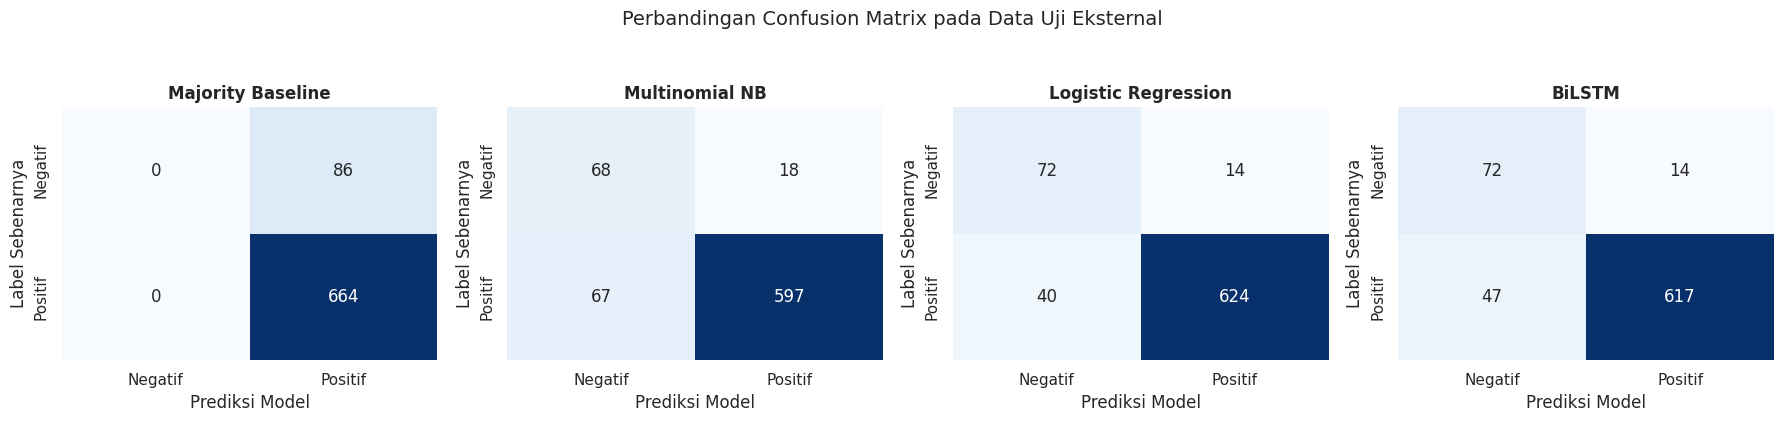

In [ ]:
# 7. Visualisasi Confusion Matrix Side-by-Side
models_to_plot = ['Majority Baseline', 'Multinomial NB', 'Logistic Regression', 'BiLSTM']
fig, axes = plt.subplots(1, len(models_to_plot), figsize=(18, 4))

for ax, model_name in zip(axes, models_to_plot):
    cm = confusion_matrix(y_test, predictions[model_name], labels=list(range(num_classes)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=target_names, yticklabels=target_names, cbar=False)
    ax.set_title(f"{model_name}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Prediksi Model")
    ax.set_ylabel("Label Sebenarnya")

plt.suptitle("Perbandingan Confusion Matrix pada Data Uji Eksternal", fontsize=14, y=1.05)
plt.tight_layout()
plt.savefig('confusion_matrices_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


## 8. Analisis Tematik & Kata Kunci: Mengapa Pengguna Puas atau Mengeluh?
Pada bagian ini, kami menganalisis ulasan pengguna berdasarkan kategori tema pedagogis dan teknis menggunakan regex yang telah diperbaiki:
1. **Energy & Heart System:** Hambatan belajar akibat pembatasan kuota nyawa (*cognitive flow interruption*).
2. **Monetization & Ads:** Frustrasi terhadap *paywall* langganan *Super/Max* dan iklan yang mengganggu.
3. **Curriculum & Grammar:** Ulasan terkait konten pembelajaran bahasa, penjelasan tata bahasa, dan akurasi terjemahan.
4. **Gamification & Streaks:** Aspek motivasional seperti *streak*, *league*, dan *XP*.
5. **Technical Bugs:** Masalah aplikasi macet (*freeze*), gagal memuat (*crash*), atau galat teknis.
6. **AI Integration & Ethics:** Persepsi terhadap fitur cerdas, otomatisasi bot, dan isu penggantian staf pengajar/penerjemah manusia (*"AI slop"*).


,Theme,Negatif,Positif
0,Energy & Heart System,12 (14.0%),4 (0.6%)
1,Monetization & Ads,3 (3.5%),4 (0.6%)
2,Curriculum & Grammar,21 (24.4%),29 (4.4%)
3,Gamification & Streaks,9 (10.5%),13 (2.0%)
4,Technical Bugs,5 (5.8%),2 (0.3%)
5,AI Integration & Ethics,7 (8.1%),0 (0.0%)


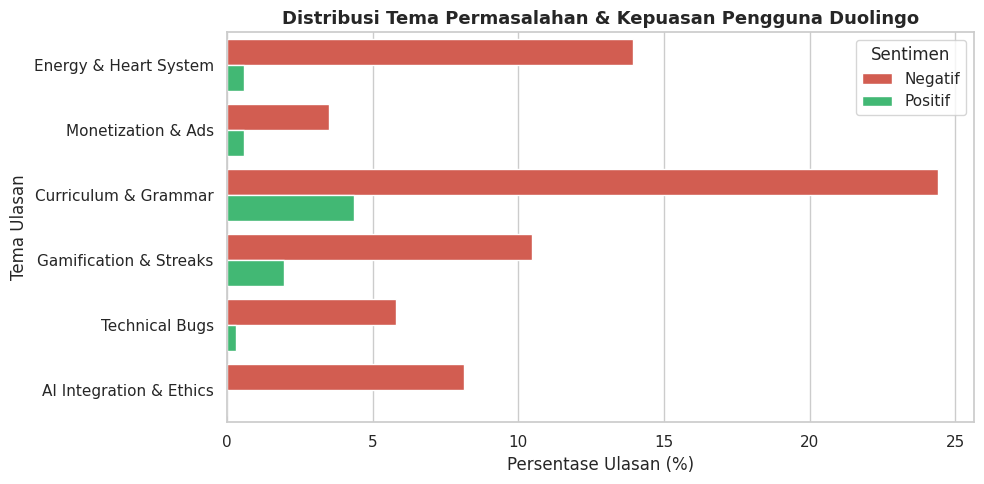

In [ ]:
# 8. Analisis Tematik Berbasis Regex yang Disempurnakan
thematic_patterns = {
    'Energy & Heart System': r'\b(?:energy|hearts?|lives|health)\b',
    'Monetization & Ads': r'\b(?:duolingo super|duolingo max|super subscription|paywall|expensive|subscription|monthly|yearly|unskippable ads?|too many ads)\b',
    'Curriculum & Grammar': r'\b(?:grammar|lessons?|sentences?|explanations?|vocabulary|mistakes?|wrong translation|pronunciation)\b',
    'Gamification & Streaks': r'\b(?:streaks?|leagues?|xp|gems?|trophies|leaderboard)\b',
    'Technical Bugs': r'\b(?:bugs?|buggy|crash(?:es|ed)?|glitch(?:es)?|error|freez\w*|broken|loading)\b',
    'AI Integration & Ethics': r'\b(?:ai\b|bots?|ai slop|firing|employees?|contractors?|replaced? with ai|generated|artificial)\b'
}

theme_summary = []

for theme_name, regex_pattern in thematic_patterns.items():
    pat = re.compile(regex_pattern, re.IGNORECASE)
    row = {'Theme': theme_name}

    for label_name in target_names:
        sub_df = df_uji[df_uji['label'] == label_name.lower()]
        hits = sub_df['clean_text'].apply(lambda t: bool(pat.search(t))).sum()
        pct = (hits / len(sub_df) * 100) if len(sub_df) > 0 else 0
        row[label_name] = f"{hits} ({pct:.1f}%)"
        row[f'{label_name}_pct'] = pct

    theme_summary.append(row)

df_theme = pd.DataFrame(theme_summary)
display(df_theme[['Theme'] + target_names])

# Visualisasi Bar Chart Tema
plot_data = []
for r in theme_summary:
    for t_name in target_names:
        plot_data.append({
            'Theme': r['Theme'],
            'Sentiment': t_name,
            'Percentage': r[f'{t_name}_pct']
        })

df_plot = pd.DataFrame(plot_data)
plt.figure(figsize=(10, 5))
sns.barplot(data=df_plot, x='Percentage', y='Theme', hue='Sentiment', palette={'Negatif': '#e74c3c', 'Positif': '#2ecc71', 'Netral': '#95a5a6'})
plt.title("Distribusi Tema Permasalahan & Kepuasan Pengguna Duolingo", fontsize=13, fontweight='bold')
plt.xlabel("Persentase Ulasan (%)")
plt.ylabel("Tema Ulasan")
plt.legend(title="Sentimen")
plt.tight_layout()
plt.savefig('thematic_distribution_duolingo.png', dpi=300, bbox_inches='tight')
plt.show()


## 9. Ekstraksi Kutipan Kualitatif untuk Naskah Paper
Bagian ini mengekstrak contoh ulasan asli pengguna yang sangat representatif untuk dikutip secara langsung pada Bab Pembahasan (*Discussion Section*) di naskah paper Anda.


In [ ]:
# 9. Ekstraksi Contoh Kutipan Kualitatif Riil
ai_pat = re.compile(thematic_patterns['AI Integration & Ethics'], re.IGNORECASE)
neg_ai_reviews = df_uji[(df_uji['label'] == 'negatif') & (df_uji['clean_text'].apply(lambda t: bool(ai_pat.search(t))))]

print(f"Ditemukan {len(neg_ai_reviews)} ulasan negatif yang secara spesifik menyinggung AI / Otomatisasi.")
print("="*80)
for idx, text in enumerate(neg_ai_reviews['clean_text'].head(6), 1):
    print(f"[{idx}] \"{text}\"\n")

print("Insight untuk Naskah Paper:")
print("- Pembelajar menyoroti pergeseran ke arah 'AI slop' dan hilangnya akurasi bahasa manusiawi.")
print("- Terdapat resistensi moral pengguna terhadap keputusan korporat mengganti pengajar/ahli bahasa manusia.")


Ditemukan 7 ulasan negatif yang secara spesifik menyinggung AI / Otomatisasi.
[1] "do not download app has been garbage for a while maybe firing the majority of the humans working their and replacing them with bots was a bad idea i am constantly loosing chess games when rhe other player gets disconnectes or stops moving after a handful of moves any time you submit a bug report they send a bs acknowledgement email and less than zero changes i would rate it minus stars if the option was available"

[2] "the ai parts are terrible and so obvious the new games which i suspect are part ai generated are also rubbish it was better before they added this stuff"

[3] "updating my review the app has gotten so worse the amount of unnecessary bloat and gacha suits added is completely unnecessary to learning instead of adding more features to premium members they added an higher paid tier for an ai generated chat mode i miss when this apps goal was about learning a language"

[4] "once i heard it wa

In [ ]:
# ===== SEL E — Kata paling menentukan menurut Logistic Regression =====
fitur = np.array(tfidf.get_feature_names_out())
koef = lr.coef_[0]   # nilai positif -> mendorong ke 'positif', negatif -> ke 'negatif'
urut = np.argsort(koef)
tabel_koef = pd.DataFrame({
    'Penanda Negatif': fitur[urut[:15]],
    'Koef. Neg': np.round(koef[urut[:15]], 2),
    'Penanda Positif': fitur[urut[::-1][:15]],
    'Koef. Pos': np.round(koef[urut[::-1][:15]], 2),
})
print(tabel_koef.to_string(index=False))

Penanda Negatif  Koef. Neg Penanda Positif  Koef. Pos
             ai     -11.18            love       5.97
            not      -5.83             fun       5.85
          worst      -5.10         amazing       5.49
         energy      -5.07           great       5.06
             no      -3.93            good       4.60
            bad      -3.88            best       4.47
        useless      -3.72           helps       3.51
          worse      -3.68       excellent       3.31
           hate      -3.61         awesome       3.26
          doesn      -3.54        learning       3.18
        used to      -3.52            nice       3.16
            ads      -3.43        the best       3.08
       horrible      -3.34            easy       2.88
         update      -3.33         perfect       2.85
          money      -3.26         helpful       2.74


/tmp/ipykernel_1129/2932496482.py:11: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  raw['bulan'] = raw['tanggal'].dt.to_period('M')


         jumlah_ulasan  rata_bintang  persen_negatif  persen_ai_semua  persen_ai_di_negatif
bulan                                                                                      
2025-01          35615          4.44             8.7              0.5                   3.6
2025-02          36642          4.50             7.9              0.4                   3.4
2025-03          38347          4.42             9.7              0.6                   3.9
2025-04          31638          4.31            12.5              3.8                  29.2
2025-05          49929          3.48            34.6             24.3                  68.9
2025-06          37119          4.24            14.3              4.7                  29.7
2025-07          33780          4.39            10.2              2.5                  20.4
2025-08          36449          4.38            10.6              2.0                  15.4
2025-09          42373          4.16            16.4              3.3           

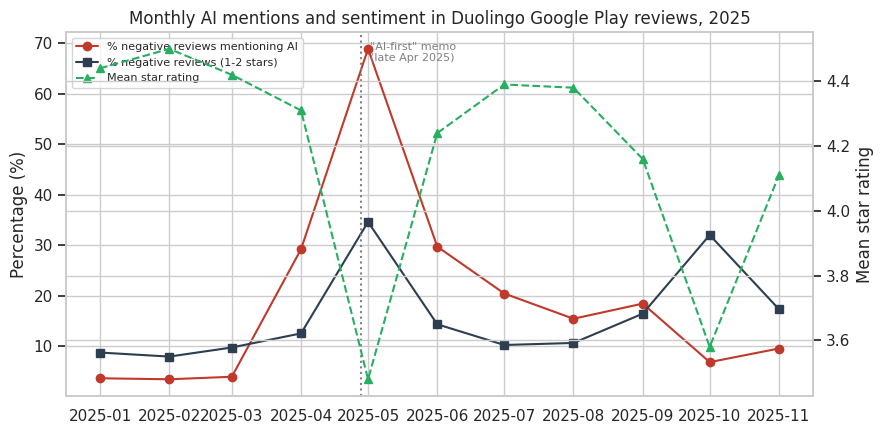

In [ ]:
# ===== SEL A — Tren bulanan ulasan yang menyebut AI (data Kaggle mentah) =====
# Wajib: upload duolingo_reviews_2025.csv (file Kaggle mentah, 73.297.733 byte) ke Colab
assert os.path.getsize('duolingo_reviews_2025.csv') == 73297733, "File Kaggle belum ter-upload utuh!"
raw = pd.read_csv('duolingo_reviews_2025.csv', low_memory=False)
raw = raw[raw['score'].astype(str).isin(['1', '2', '3', '4', '5'])].copy()
raw['score'] = raw['score'].astype(int)
raw['tanggal'] = pd.to_datetime(raw['created_at'], errors='coerce')
raw = raw.dropna(subset=['tanggal', 'content'])
raw['clean_text'] = raw['content'].apply(clean_text)
raw = raw[raw['clean_text'].str.split().str.len() >= 2]
raw['bulan'] = raw['tanggal'].dt.to_period('M')
raw['negatif'] = raw['score'] <= 2
pola_ai = re.compile(r'\b(?:ai|bots?|ai slop|firing|employees?|contractors?|replaced? with ai|generated|artificial)\b')
raw['sebut_ai'] = raw['clean_text'].apply(lambda t: bool(pola_ai.search(t)))
raw = raw[(raw['bulan'] >= '2025-01') & (raw['bulan'] <= '2025-11')]   # hanya bulan yang datanya penuh

tren = raw.groupby('bulan').agg(
    jumlah_ulasan=('score', 'size'),
    rata_bintang=('score', 'mean'),
    persen_negatif=('negatif', 'mean'),
    persen_ai_semua=('sebut_ai', 'mean'),
)
tren['persen_ai_di_negatif'] = raw[raw['negatif']].groupby('bulan')['sebut_ai'].mean()
for k in ['persen_negatif', 'persen_ai_semua', 'persen_ai_di_negatif']:
    tren[k] = (100 * tren[k]).round(1)
tren['rata_bintang'] = tren['rata_bintang'].round(2)
print(tren.to_string())

fig, ax1 = plt.subplots(figsize=(9, 4.5))
x = tren.index.to_timestamp()
ax1.plot(x, tren['persen_ai_di_negatif'], marker='o', color='#c0392b', label='% negative reviews mentioning AI')
ax1.plot(x, tren['persen_negatif'], marker='s', color='#2c3e50', label='% negative reviews (1-2 stars)')
ax1.set_ylabel('Percentage (%)')
ax2 = ax1.twinx()
ax2.plot(x, tren['rata_bintang'], marker='^', linestyle='--', color='#27ae60', label='Mean star rating')
ax2.set_ylabel('Mean star rating')
ax1.axvline(pd.Timestamp('2025-04-28'), color='grey', linestyle=':')
ax1.text(pd.Timestamp('2025-05-02'), ax1.get_ylim()[1] * 0.92, '"AI-first" memo\n(late Apr 2025)', fontsize=8, color='grey')
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)
plt.title('Monthly AI mentions and sentiment in Duolingo Google Play reviews, 2025')
plt.tight_layout()
plt.savefig('tren_ai_bulanan.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ===== LANGKAH 1: Tabel hasil final (tanpa melatih ulang) =====
eval_rows = []
for name, y_pred in predictions.items():
    f1_pc = f1_score(y_test, y_pred, average=None,
                     labels=list(range(num_classes)), zero_division=0)
    row = {
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 3),
        'Balanced Acc': round(balanced_accuracy_score(y_test, y_pred), 3),
        'Macro Precision': round(precision_score(y_test, y_pred, average='macro', zero_division=0), 3),
        'Macro Recall': round(recall_score(y_test, y_pred, average='macro', zero_division=0), 3),
        'Macro F1': round(f1_score(y_test, y_pred, average='macro', zero_division=0), 3),
    }
    for i, t_name in enumerate(target_names):
        row[f'F1 {t_name}'] = round(f1_pc[i], 3)
    eval_rows.append(row)

df_eval_final = pd.DataFrame(eval_rows)
df_eval_final['Model'] = df_eval_final['Model'].replace(
    {'Majority Baseline': 'Majority Baseline (always positive)'})

# Pengaman: pastikan baseline sudah versi yang benar
assert df_eval_final.iloc[0]['Accuracy'] > 0.8, "Baseline masih versi lama! Jalankan sel 12 dulu."

display(df_eval_final)
df_eval_final.to_csv('tabel_hasil_model_final.csv', index=False)

,Model,Accuracy,Balanced Acc,Macro Precision,Macro Recall,Macro F1,F1 Negatif,F1 Positif
0,Majority Baseline (always positive),0.885,0.500,0.443,0.500,0.470,0.000,0.939
1,Multinomial NB,0.887,0.845,0.737,0.845,0.774,0.615,0.934
2,Logistic Regression,0.928,0.888,0.810,0.888,0.843,0.727,0.959
3,BiLSTM,0.919,0.883,0.791,0.883,0.828,0.702,0.953


In [ ]:
#===== SEL D1 — Bootstrap 95% CI Macro F1 + uji McNemar =====
from scipy.stats import binomtest
rng = np.random.default_rng(SEED)
yt = np.asarray(y_test)
n = len(yt)
B = 2000
hasil_ci = []
for nama, pred in predictions.items():
    pred = np.asarray(pred)
    skor = []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        skor.append(f1_score(yt[idx], pred[idx], average='macro', zero_division=0))
    lo, hi = np.percentile(skor, [2.5, 97.5])
    hasil_ci.append({'Model': nama,
                     'Macro F1': round(f1_score(yt, pred, average='macro', zero_division=0), 3),
                     '95% CI': f"[{lo:.3f}, {hi:.3f}]"})
print(pd.DataFrame(hasil_ci).to_string(index=False))


def mcnemar_exact(a, b):
    a, b = np.asarray(a), np.asarray(b)
    hanya_a = int(np.sum((a == yt) & (b != yt)))
    hanya_b = int(np.sum((a != yt) & (b == yt)))
    p = binomtest(hanya_a, hanya_a + hanya_b, 0.5).pvalue if hanya_a + hanya_b > 0 else 1.0
    return hanya_a, hanya_b, p


for m1, m2 in [('Logistic Regression', 'BiLSTM'), ('Logistic Regression', 'Multinomial NB'), ('BiLSTM', 'Multinomial NB')]:
    a, b, p = mcnemar_exact(predictions[m1], predictions[m2])
    print(f"McNemar {m1} vs {m2}: benar hanya di {m1} = {a}, hanya di {m2} = {b}, p = {p:.3f}")

              Model  Macro F1         95% CI
  Majority Baseline     0.470 [0.464, 0.476]
     Multinomial NB     0.774 [0.730, 0.815]
Logistic Regression     0.843 [0.803, 0.881]
             BiLSTM     0.828 [0.785, 0.867]
McNemar Logistic Regression vs BiLSTM: benar hanya di Logistic Regression = 14, hanya di BiLSTM = 7, p = 0.189
McNemar Logistic Regression vs Multinomial NB: benar hanya di Logistic Regression = 36, hanya di Multinomial NB = 5, p = 0.000
McNemar BiLSTM vs Multinomial NB: benar hanya di BiLSTM = 38, hanya di Multinomial NB = 14, p = 0.001


In [ ]:
# ===== SEL D2 — BiLSTM dengan 5 seed (mean ± SD) =====
# Tidak mengubah predictions['BiLSTM'] yang sudah ada.
def latih_bilstm(seed):
    tf.keras.utils.set_random_seed(seed)
    m = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(VOCAB_SIZE, EMBEDDING_DIM),
        SpatialDropout1D(0.3),
        Bidirectional(LSTM(64, return_sequences=True)),
        Dropout(0.3),
        Bidirectional(LSTM(32)),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(num_classes, activation='softmax'),
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    m.fit(X_train_pad, y_train.values, epochs=12, batch_size=64,
          validation_data=(X_val_pad, y_val.values),
          callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
                     ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)],
          verbose=0)
    p = np.argmax(m.predict(X_test_pad, verbose=0), axis=1)
    return {'seed': seed,
            'Accuracy': accuracy_score(y_test, p),
            'Balanced Acc': balanced_accuracy_score(y_test, p),
            'Macro F1': f1_score(y_test, p, average='macro'),
            'F1 Negatif': f1_score(y_test, p, average=None)[0]}


hasil_seed = pd.DataFrame([latih_bilstm(s) for s in [1, 2, 3, 4, 5]])
print(hasil_seed.round(3).to_string(index=False))
print("\nRata-rata ± SD:")
for k in ['Accuracy', 'Balanced Acc', 'Macro F1', 'F1 Negatif']:
    print(f"{k:13s}: {hasil_seed[k].mean():.3f} ± {hasil_seed[k].std():.3f}")

 seed  Accuracy  Balanced Acc  Macro F1  F1 Negatif
    1     0.924         0.881     0.835       0.714
    2     0.924         0.861     0.829       0.702
    3     0.933         0.881     0.849       0.737
    4     0.909         0.873     0.812       0.676
    5     0.921         0.885     0.832       0.709

Rata-rata ± SD:
Accuracy     : 0.922 ± 0.009
Balanced Acc : 0.876 ± 0.010
Macro F1     : 0.831 ± 0.013
F1 Negatif   : 0.708 ± 0.022


In [ ]:
# ===== SEL B1 — Ambil 100 ulasan AI untuk coding kualitatif =====
neg_ai = raw[raw['negatif'] & raw['sebut_ai']].copy()
sampel_b = neg_ai.sample(n=100, random_state=SEED).reset_index(drop=True)
sampel_b.insert(0, 'id', [f'B{i+1:03d}' for i in range(len(sampel_b))])
lembar_b = sampel_b[['id', 'content']].rename(columns={'content': 'ulasan'})
lembar_b['kode'] = ''
lembar_b['catatan'] = ''
lembar_b.to_csv('coding_B_putaran1.csv', index=False)

ulang_b = lembar_b.sample(n=30, random_state=7)[['id', 'ulasan']].copy()   # urutan diacak
ulang_b['kode'] = ''
ulang_b.to_csv('coding_B_putaran2_JANGAN_DIBUKA_DULU.csv', index=False)
print(f"Populasi ulasan negatif yang menyebut AI: {len(neg_ai):,}")
print("Tersimpan: coding_B_putaran1.csv (100) dan coding_B_putaran2_JANGAN_DIBUKA_DULU.csv (30)")

Populasi ulasan negatif yang menyebut AI: 19,254
Tersimpan: coding_B_putaran1.csv (100) dan coding_B_putaran2_JANGAN_DIBUKA_DULU.csv (30)


In [ ]:
# ===== SEL C1 — Ambil 100 ulasan uji untuk validasi label bintang =====
sampel_c = df_uji.sample(n=100, random_state=SEED).reset_index(drop=True)
sampel_c.insert(0, 'id', [f'C{i+1:03d}' for i in range(len(sampel_c))])
sampel_c[['id', 'content']].rename(columns={'content': 'ulasan'}).assign(label_manual='') \
    .to_csv('validasi_C_isi_label.csv', index=False)          # tanpa bintang, supaya penilaian tidak bias
sampel_c[['id', 'score', 'label']].to_csv('validasi_C_kunci_bintang.csv', index=False)
print("Tersimpan: validasi_C_isi_label.csv (diisi) dan validasi_C_kunci_bintang.csv (jangan dilihat dulu)")

Tersimpan: validasi_C_isi_label.csv (diisi) dan validasi_C_kunci_bintang.csv (jangan dilihat dulu)


In [ ]:
# ===== SEL B2 & C2 — Hitung hasil setelah file diisi dan di-upload kembali =====
from sklearn.metrics import cohen_kappa_score
b1 = pd.read_csv('coding_B_putaran1_terisi.csv')
b2 = pd.read_csv('coding_B_putaran2_terisi.csv')
b1['kode'] = b1['kode'].astype(str).str.strip().str.upper()
b2['kode'] = b2['kode'].astype(str).str.strip().str.upper()
print("Distribusi kode (100 ulasan):")
print(b1['kode'].value_counts().to_string())
print((100 * b1['kode'].value_counts(normalize=True)).round(1).to_string())
gabung_b = b1[['id', 'kode']].merge(b2[['id', 'kode']], on='id', suffixes=('_1', '_2'))
print(f"\nIntra-rater: {len(gabung_b)} ulasan, kesepakatan = {(gabung_b['kode_1'] == gabung_b['kode_2']).mean():.1%}, "
      f"Cohen's kappa = {cohen_kappa_score(gabung_b['kode_1'], gabung_b['kode_2']):.3f}")

c_isi = pd.read_csv('validasi_C_isi_label_terisi.csv')
c_kunci = pd.read_csv('validasi_C_kunci_bintang.csv')
c = c_isi.merge(c_kunci, on='id')
c['label_manual'] = c['label_manual'].astype(str).str.strip().str.lower()
print("\nLabel manual:", c['label_manual'].value_counts().to_dict())
c_jelas = c[c['label_manual'].isin(['positif', 'negatif'])]
print(f"Kesesuaian label bintang vs label manual (tanpa 'campuran'): {(c_jelas['label'] == c_jelas['label_manual']).mean():.1%} "
      f"dari {len(c_jelas)} ulasan; Cohen's kappa = {cohen_kappa_score(c_jelas['label'], c_jelas['label_manual']):.3f}")
print(c[c['label'] != c['label_manual']][['id', 'score', 'label', 'label_manual', 'ulasan']].to_string(index=False))

Distribusi kode (100 ulasan):
kode
LABOUR     33
TRUST      32
QUALITY    29
FEATURE     3
OTHER       3
kode
LABOUR     33.0
TRUST      32.0
QUALITY    29.0
FEATURE     3.0
OTHER       3.0

Intra-rater: 30 ulasan, kesepakatan = 50.0%, Cohen's kappa = 0.371

Label manual: {'positif': 72, 'campuran': 19, 'negatif': 9}
Kesesuaian label bintang vs label manual (tanpa 'campuran'): 96.3% dari 81 ulasan; Cohen's kappa = 0.780
  id  score   label label_manual                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           ulasan
C002      2 negatif     campuran              

In [ ]:
# ===== LANGKAH 2: Diagnosis ketidakkonsistenan coding B =====
b1 = pd.read_csv('coding_B_putaran1_terisi.csv')
b2 = pd.read_csv('coding_B_putaran2_terisi.csv')
for d in (b1, b2):
    d['kode'] = d['kode'].astype(str).str.strip().str.upper()

g = b1[['id', 'kode', 'ulasan']].merge(b2[['id', 'kode']], on='id', suffixes=('_1', '_2'))

print("Crosstab (baris = putaran 1, kolom = putaran 2):")
print(pd.crosstab(g['kode_1'], g['kode_2'], margins=True))

beda = g[g['kode_1'] != g['kode_2']]
print(f"\nBerbeda: {len(beda)} dari {len(g)}\n")
pd.set_option('display.max_colwidth', 500)
print(beda[['id', 'kode_1', 'kode_2', 'ulasan']].to_string(index=False))

Crosstab (baris = putaran 1, kolom = putaran 2):
kode_2   FEATURE  LABOUR  OTHER  QUALITY  TRUST  All
kode_1                                              
FEATURE        0       0      0        1      0    1
LABOUR         1       8      0        0      1   10
QUALITY        1       0      0        6      2    9
TRUST          0       0      9        0      1   10
All            2       8      9        7      4   30

Berbeda: 15 dari 30

  id  kode_1  kode_2                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             ulasan
B003   TRUST   OTHER                  

In [ ]:
# ===== LANGKAH 3: Sampel coding B versi 2 (stratifikasi Mei vs bulan lain) =====
neg_ai = raw[raw['negatif'] & raw['sebut_ai']].copy()
neg_ai['periode'] = np.where(neg_ai['bulan'] == pd.Period('2025-05', 'M'),
                             'Mei 2025', 'Bulan lain')
print(neg_ai['periode'].value_counts())

s_mei  = neg_ai[neg_ai['periode'] == 'Mei 2025'].sample(n=50, random_state=SEED)
s_lain = neg_ai[neg_ai['periode'] == 'Bulan lain'].sample(n=50, random_state=SEED)
sampel = pd.concat([s_mei, s_lain]).sample(frac=1, random_state=SEED).reset_index(drop=True)
sampel.insert(0, 'id', [f'B2_{i+1:03d}' for i in range(len(sampel))])

# File untuk dikode (tanpa info periode/bintang agar tidak bias)
lembar = sampel[['id', 'content']].rename(columns={'content': 'ulasan'})
lembar['kode'] = ''
lembar['kode_sekunder'] = ''
lembar['catatan'] = ''
lembar.to_csv('coding_B2_putaran1.csv', index=False)

# Kunci periode (jangan dilihat saat mengode)
kunci = sampel[['id', 'periode', 'score']].copy()
kunci['bulan'] = sampel['bulan'].astype(str)
kunci.to_csv('coding_B2_kunci_periode.csv', index=False)

# 30 ulasan untuk kode ulang (urutan diacak)
ulang = lembar.sample(n=30, random_state=7)[['id', 'ulasan']].copy()
ulang['kode'] = ''
ulang.to_csv('coding_B2_putaran2_JANGAN_DIBUKA_DULU.csv', index=False)

print("Tersimpan: coding_B2_putaran1.csv (100), coding_B2_putaran2_JANGAN_DIBUKA_DULU.csv (30),")
print("           coding_B2_kunci_periode.csv (jangan dibuka)")

periode
Mei 2025      11912
Bulan lain     7342
Name: count, dtype: int64
Tersimpan: coding_B2_putaran1.csv (100), coding_B2_putaran2_JANGAN_DIBUKA_DULU.csv (30),
           coding_B2_kunci_periode.csv (jangan dibuka)


In [21]:
# ===== LANGKAH 4: LR tanpa kata AI (uji ketergantungan pada kata AI) =====
from scipy.stats import binomtest

pola_mask = re.compile(r'\b(?:ai|bots?|chatgpt|gpt|slop|firing|fired|employees?|contractors?|generated|artificial|automation|automated)\b')
mask = lambda t: pola_mask.sub(' ', t)

tfidf_m = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
Xtr_m = tfidf_m.fit_transform(X_train_raw.apply(mask))
Xte_m = tfidf_m.transform(X_test_raw.apply(mask))
lr_m = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xtr_m, y_train)

yt = np.asarray(y_test)
p_asli = np.asarray(predictions['Logistic Regression'])
p_mask = lr_m.predict(Xte_m)

baris = []
for nama, p in [('LR asli', p_asli), ('LR tanpa kata AI', p_mask)]:
    baris.append({
        'Model': nama,
        'Accuracy': round(accuracy_score(yt, p), 3),
        'Balanced Acc': round(balanced_accuracy_score(yt, p), 3),
        'Macro F1': round(f1_score(yt, p, average='macro'), 3),
        'F1 Negatif': round(f1_score(yt, p, pos_label=0), 3),
    })
tabel_mask = pd.DataFrame(baris)
display(tabel_mask)
tabel_mask.to_csv('tabel_lr_tanpa_kata_ai.csv', index=False)

# McNemar: asli vs tanpa kata AI
a = int(np.sum((p_asli == yt) & (p_mask != yt)))
b = int(np.sum((p_asli != yt) & (p_mask == yt)))
pval = binomtest(a, a + b, 0.5).pvalue if a + b > 0 else 1.0
print(f"McNemar: benar hanya di LR asli = {a}, hanya di LR tanpa kata AI = {b}, p = {pval:.3f}")

# Di mana penurunannya terjadi? (ulasan uji yang memuat kata AI)
ada_ai = X_test_raw.apply(lambda t: bool(pola_mask.search(t))).values
print(f"\nUlasan uji yang memuat kata AI: {ada_ai.sum()} dari {len(yt)}")
print(f"Akurasi di ulasan itu  : asli = {accuracy_score(yt[ada_ai], p_asli[ada_ai]):.3f}, tanpa kata AI = {accuracy_score(yt[ada_ai], p_mask[ada_ai]):.3f}")
print(f"Akurasi di sisanya     : asli = {accuracy_score(yt[~ada_ai], p_asli[~ada_ai]):.3f}, tanpa kata AI = {accuracy_score(yt[~ada_ai], p_mask[~ada_ai]):.3f}")

# Penanda negatif teratas setelah kata AI dibuang
f = np.array(tfidf_m.get_feature_names_out())
k = lr_m.coef_[0]
print("\nPenanda negatif teratas (tanpa kata AI):", list(f[np.argsort(k)[:12]]))

,Model,Accuracy,Balanced Acc,Macro F1,F1 Negatif
0,LR asli,0.928,0.888,0.843,0.727
1,LR tanpa kata AI,0.920,0.884,0.830,0.706


McNemar: benar hanya di LR asli = 6, hanya di LR tanpa kata AI = 0, p = 0.031

Ulasan uji yang memuat kata AI: 10 dari 750
Akurasi di ulasan itu  : asli = 1.000, tanpa kata AI = 1.000
Akurasi di sisanya     : asli = 0.927, tanpa kata AI = 0.919

Penanda negatif teratas (tanpa kata AI): ['not', 'first', 'worst', 'energy', 'bad', 'no', 'company', 'worse', 'replacing', 'used to', 'doesn', 'human']


In [22]:
# ===== LANGKAH 5: Hasil coding B versi 2 =====
from sklearn.metrics import cohen_kappa_score
KODE = ['LABOUR', 'QUALITY', 'FEATURE', 'REJECT', 'INCIDENTAL', 'OTHER']

def baca(path):
    d = pd.read_csv(path)
    d['kode'] = d['kode'].fillna('').astype(str).str.strip().str.upper()
    return d

b1 = baca('coding_B2_putaran1_terisi.csv')
b2 = baca('coding_B2_putaran2_terisi.csv')
kunci = pd.read_csv('coding_B2_kunci_periode.csv')

# 1. Pemeriksaan kode tidak valid / kosong
for nama, d in [('Putaran 1', b1), ('Putaran 2', b2)]:
    salah = d[~d['kode'].isin(KODE)]
    print(f"{nama}: {len(d)} baris, kode tidak valid/kosong = {len(salah)}")
    if len(salah):
        print(salah[['id', 'kode']].to_string(index=False))

# 2. Distribusi kode (putaran 1)
dist = b1['kode'].value_counts().reindex(KODE, fill_value=0)
print("\nDistribusi kode, 100 ulasan:")
print(pd.DataFrame({'n': dist, '%': (100 * dist / len(b1)).round(1)}).to_string())

# 3. Distribusi per periode (Mei 2025 vs bulan lain)
b1k = b1.merge(kunci[['id', 'periode']], on='id')
ct = pd.crosstab(b1k['kode'], b1k['periode']).reindex(KODE, fill_value=0)
print("\nJumlah per periode:")
print(ct.to_string())
print("\nPersen per periode (kolom = 100%):")
print((100 * ct / ct.sum()).round(1).to_string())

# 4. Kode sekunder (jika diisi)
if 'kode_sekunder' in b1.columns:
    sek = b1['kode_sekunder'].fillna('').astype(str).str.strip().str.upper()
    sek = sek[sek != '']
    print(f"\nUlasan dengan kode sekunder: {len(sek)}")
    if len(sek): print(sek.value_counts().to_string())

# 5. Konsistensi intra-rater (30 ulasan, putaran 1 vs putaran 2)
g = b1[['id', 'kode', 'ulasan']].merge(b2[['id', 'kode']], on='id', suffixes=('_1', '_2'))
kappa = cohen_kappa_score(g['kode_1'], g['kode_2'])
sepakat = (g['kode_1'] == g['kode_2']).mean()

rng = np.random.default_rng(SEED)
bs = []
for _ in range(2000):
    i = rng.integers(0, len(g), len(g))
    if g['kode_1'].iloc[i].nunique() > 1 or g['kode_2'].iloc[i].nunique() > 1:
        bs.append(cohen_kappa_score(g['kode_1'].iloc[i], g['kode_2'].iloc[i]))
lo, hi = np.percentile(bs, [2.5, 97.5])
print(f"\nIntra-rater: n = {len(g)}, kesepakatan = {sepakat:.1%}, Cohen's kappa = {kappa:.3f} (95% CI bootstrap [{lo:.3f}, {hi:.3f}])")

print("\nCrosstab (baris = putaran 1, kolom = putaran 2):")
print(pd.crosstab(g['kode_1'], g['kode_2'], margins=True).to_string())

beda = g[g['kode_1'] != g['kode_2']]
print(f"\nKode berbeda: {len(beda)} dari {len(g)}")
pd.set_option('display.max_colwidth', 400)
if len(beda): print(beda[['id', 'kode_1', 'kode_2', 'ulasan']].to_string(index=False))

# 6. Simpan tabel untuk naskah
ct.to_csv('tabel_coding_B2_per_periode.csv')

Putaran 1: 100 baris, kode tidak valid/kosong = 95
    id kode
B2_006     
B2_007     
B2_008     
B2_009     
B2_010     
B2_011     
B2_012     
B2_013     
B2_014     
B2_015     
B2_016     
B2_017     
B2_018     
B2_019     
B2_020     
B2_021     
B2_022     
B2_023     
B2_024     
B2_025     
B2_026     
B2_027     
B2_028     
B2_029     
B2_030     
B2_031     
B2_032     
B2_033     
B2_034     
B2_035     
B2_036     
B2_037     
B2_038     
B2_039     
B2_040     
B2_041     
B2_042     
B2_043     
B2_044     
B2_045     
B2_046     
B2_047     
B2_048     
B2_049     
B2_050     
B2_051     
B2_052     
B2_053     
B2_054     
B2_055     
B2_056     
B2_057     
B2_058     
B2_059     
B2_060     
B2_061     
B2_062     
B2_063     
B2_064     
B2_065     
B2_066     
B2_067     
B2_068     
B2_069     
B2_070     
B2_071     
B2_072     
B2_073     
B2_074     
B2_075     
B2_076     
B2_077     
B2_078     
B2_079     
B2_080     
B2_081     
B2_082     
B2_083     
B

In [23]:
d = pd.read_csv('coding_B2_putaran1_terisi.csv')
print(d['kode'].notna().sum(), "dari", len(d), "terisi")

5 dari 100 terisi


In [24]:
# ===== LANGKAH 5b: File 70 ulasan sisa + file putaran 3 =====
def baca2(path):
    d = pd.read_csv(path)
    d['kode'] = d['kode'].fillna('').astype(str).str.strip().str.upper()
    return d

b1 = baca2('coding_B2_putaran1_terisi.csv')
b2 = baca2('coding_B2_putaran2_terisi.csv')

# 70 ulasan yang belum punya kode "pertama" dari putaran 2
sisa = b1[~b1['id'].isin(set(b2['id']))][['id', 'ulasan', 'kode', 'kode_sekunder', 'catatan']].copy()
sisa.to_csv('coding_B2_sisa70.csv', index=False)
print(f"Sisa: {len(sisa)} ulasan, sudah terkode: {(sisa['kode'] != '').sum()}")

# Putaran 3: 30 ulasan yang sama, urutan diacak, kode dikosongkan
r3 = b2[['id', 'ulasan']].sample(frac=1, random_state=11).copy()
r3['kode'] = ''
r3.to_csv('coding_B2_putaran3_JANGAN_DIBUKA_DULU.csv', index=False)
print("Tersimpan: coding_B2_sisa70.csv dan coding_B2_putaran3_JANGAN_DIBUKA_DULU.csv")

Sisa: 70 ulasan, sudah terkode: 4
Tersimpan: coding_B2_sisa70.csv dan coding_B2_putaran3_JANGAN_DIBUKA_DULU.csv


In [35]:
# ===== SEL C2 (versi 2): validasi label bintang vs label manual =====
from sklearn.metrics import cohen_kappa_score
VALID = ['positif', 'negatif', 'campuran', 'tidak_informatif']

def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return centre - half, centre + half

c_isi = pd.read_csv('validasi_C_isi_label_terisi.csv')
c_kunci = pd.read_csv('validasi_C_kunci_bintang.csv')
c = c_isi.merge(c_kunci, on='id')
c['label_manual'] = (c['label_manual'].fillna('').astype(str)
                     .str.strip().str.lower().str.replace(' ', '_'))

# 1. Pemeriksaan label tidak valid / kosong
salah = c[~c['label_manual'].isin(VALID)]
print(f"Total ulasan: {len(c)}, label tidak valid/kosong: {len(salah)}")
if len(salah):
    print(salah[['id', 'label_manual']].to_string(index=False))

# 2. Distribusi label manual
dist = c['label_manual'].value_counts().reindex(VALID, fill_value=0)
print("\nDistribusi label manual:")
print(dist.to_string())

# 3. Tabel silang: label bintang (baris) vs label manual (kolom)
print("\nLabel bintang (baris) vs label manual (kolom):")
print(pd.crosstab(c['label'], c['label_manual']).reindex(
    index=['negatif', 'positif'], columns=VALID, fill_value=0).to_string())

# 4. Kesesuaian pada ulasan berpolaritas jelas
jelas = c[c['label_manual'].isin(['positif', 'negatif'])]
n_j = len(jelas)
k_j = int((jelas['label'] == jelas['label_manual']).sum())
lo, hi = wilson(k_j, n_j)
kap = cohen_kappa_score(jelas['label'], jelas['label_manual'])
print(f"\nUlasan berpolaritas jelas: {n_j} dari {len(c)}")
print(f"Kesesuaian: {k_j}/{n_j} = {k_j/n_j:.1%} (95% CI Wilson [{lo:.1%}, {hi:.1%}]), Cohen's kappa = {kap:.3f}")

# 5. Proporsi ulasan yang tidak bisa dinilai polaritasnya
tak_jelas = int(c['label_manual'].isin(['campuran', 'tidak_informatif']).sum())
lo2, hi2 = wilson(tak_jelas, len(c))
print(f"Campuran + tidak informatif: {tak_jelas}/{len(c)} = {tak_jelas/len(c):.1%} (95% CI [{lo2:.1%}, {hi2:.1%}])")

# 6. Kesesuaian jika campuran/tidak informatif dihitung sebagai 'tidak sesuai'
sesuai_semua = int((c['label'] == c['label_manual']).sum())
print(f"Kesesuaian pada seluruh sampel (konservatif): {sesuai_semua}/{len(c)} = {sesuai_semua/len(c):.1%}")

# 7. Ulasan yang tidak sesuai
pd.set_option('display.max_colwidth', 300)
beda = c[c['label'] != c['label_manual']][['id', 'score', 'label', 'label_manual', 'ulasan']]
print(f"\nUlasan tidak sesuai: {len(beda)}")
print(beda.to_string(index=False))

Total ulasan: 100, label tidak valid/kosong: 0

Distribusi label manual:
label_manual
positif             72
negatif              8
campuran            14
tidak_informatif     6

Label bintang (baris) vs label manual (kolom):
label_manual  positif  negatif  campuran  tidak_informatif
label                                                     
negatif             0        6         5                 1
positif            72        2         9                 5

Ulasan berpolaritas jelas: 80 dari 100
Kesesuaian: 78/80 = 97.5% (95% CI Wilson [91.3%, 99.3%]), Cohen's kappa = 0.844
Campuran + tidak informatif: 20/100 = 20.0% (95% CI [13.3%, 28.9%])
Kesesuaian pada seluruh sampel (konservatif): 78/100 = 78.0%

Ulasan tidak sesuai: 22
  id  score   label     label_manual                                                                                                                                                                                                                                    

In [26]:
# ===== LANGKAH 5b (revisi): File 70 ulasan sisa + file putaran 3 =====
def baca2(path):
    d = pd.read_csv(path)
    d['kode'] = d['kode'].fillna('').astype(str).str.strip().str.upper()
    return d

b1 = baca2('coding_B2_putaran1_terisi.csv')
b2 = baca2('coding_B2_putaran2_terisi.csv')

sisa = b1[~b1['id'].isin(set(b2['id']))][['id', 'ulasan']].copy()
sisa['kode'] = ''
sisa['kode_sekunder'] = ''
sisa['catatan'] = ''
sisa.to_csv('coding_B2_sisa70.csv', index=False)
print(f"Sisa untuk dikode: {len(sisa)} ulasan")      # harus 70

r3 = b2[['id', 'ulasan']].sample(frac=1, random_state=11).copy()
r3['kode'] = ''
r3.to_csv('coding_B2_putaran3_JANGAN_DIBUKA_DULU.csv', index=False)
print(f"Putaran 3: {len(r3)} ulasan (urutan diacak)")  # harus 30

Sisa untuk dikode: 70 ulasan
Putaran 3: 30 ulasan (urutan diacak)


In [27]:
# ===== LANGKAH 5c: Gabungan kode B2 (70 sisa + 30 ulasan) + kappa jika putaran 3 ada =====
import os
from sklearn.metrics import cohen_kappa_score
KODE = ['LABOUR', 'QUALITY', 'FEATURE', 'REJECT', 'INCIDENTAL', 'OTHER']

def baca(path):
    d = pd.read_csv(path)
    d['kode'] = d['kode'].fillna('').astype(str).str.strip().str.upper()
    return d

s70 = baca('coding_B2_sisa70_terisi.csv')
r2  = baca('coding_B2_putaran2_terisi.csv')
kunci = pd.read_csv('coding_B2_kunci_periode.csv')

# 1. Pemeriksaan kelengkapan
print(f"Sisa 70: {len(s70)} baris, terisi valid = {s70['kode'].isin(KODE).sum()}")
bad = s70[~s70['kode'].isin(KODE)]
if len(bad):
    print("Kode tidak valid/kosong:"); print(bad[['id', 'kode']].to_string(index=False))

# 2. 30 ulasan: pakai putaran 3 jika sudah ada, kalau belum pakai putaran 2 (sementara)
ada_r3 = os.path.exists('coding_B2_putaran3_terisi.csv')
if ada_r3:
    r3 = baca('coding_B2_putaran3_terisi.csv')
    print(f"Putaran 3: {len(r3)} baris, valid = {r3['kode'].isin(KODE).sum()}")
    tiga = r3[['id', 'ulasan', 'kode']]
    sumber30 = 'putaran 3 (FINAL)'
else:
    tiga = r2[['id', 'ulasan', 'kode']]
    sumber30 = 'putaran 2 (SEMENTARA)'
print(f"Sumber kode 30 ulasan: {sumber30}")

gab = pd.concat([s70[['id', 'ulasan', 'kode']], tiga], ignore_index=True)
gab = gab.merge(kunci[['id', 'periode']], on='id')
print(f"\nTotal ulasan terkode: {len(gab)} (harus 100)")

# 3. Distribusi dan per periode
dist = gab['kode'].value_counts().reindex(KODE, fill_value=0)
print("\nDistribusi kode:")
print(pd.DataFrame({'n': dist, '%': (100 * dist / len(gab)).round(1)}).to_string())

ct = pd.crosstab(gab['kode'], gab['periode']).reindex(KODE, fill_value=0)
print("\nJumlah per periode:"); print(ct.to_string())
print("\nPersen per periode (kolom = 100%):"); print((100 * ct / ct.sum()).round(1).to_string())
ct.to_csv('tabel_coding_B2_per_periode.csv')

# 4. Kappa intra-rater (putaran 2 vs putaran 3) hanya jika putaran 3 sudah ada
if ada_r3:
    g = r2[['id', 'kode']].merge(r3[['id', 'kode']], on='id', suffixes=('_2', '_3'))
    kappa = cohen_kappa_score(g['kode_2'], g['kode_3'])
    sepakat = (g['kode_2'] == g['kode_3']).mean()
    rng = np.random.default_rng(SEED); bs = []
    for _ in range(2000):
        i = rng.integers(0, len(g), len(g))
        a, b = g['kode_2'].iloc[i], g['kode_3'].iloc[i]
        if a.nunique() > 1 or b.nunique() > 1:
            bs.append(cohen_kappa_score(a, b))
    lo, hi = np.percentile(bs, [2.5, 97.5])
    print(f"\nIntra-rater (putaran 2 vs 3): n = {len(g)}, kesepakatan = {sepakat:.1%}, "
          f"kappa = {kappa:.3f} (95% CI bootstrap [{lo:.3f}, {hi:.3f}])")
    print("\nCrosstab (baris = putaran 2, kolom = putaran 3):")
    print(pd.crosstab(g['kode_2'], g['kode_3'], margins=True).to_string())
    beda = g[g['kode_2'] != g['kode_3']].merge(r2[['id', 'ulasan']], on='id')
    pd.set_option('display.max_colwidth', 300)
    print(f"\nKode berbeda: {len(beda)} dari {len(g)}")
    if len(beda): print(beda[['id', 'kode_2', 'kode_3', 'ulasan']].to_string(index=False))
else:
    print("\nPutaran 3 belum ada, jadi kappa belum bisa dihitung.")

Sisa 70: 70 baris, terisi valid = 70
Putaran 3: 30 baris, valid = 30
Sumber kode 30 ulasan: putaran 3 (FINAL)

Total ulasan terkode: 100 (harus 100)

Distribusi kode:
             n     %
kode                
LABOUR      26  26.0
QUALITY     16  16.0
FEATURE      5   5.0
REJECT      51  51.0
INCIDENTAL   1   1.0
OTHER        1   1.0

Jumlah per periode:
periode     Bulan lain  Mei 2025
kode                            
LABOUR              11        15
QUALITY             11         5
FEATURE              4         1
REJECT              23        28
INCIDENTAL           1         0
OTHER                0         1

Persen per periode (kolom = 100%):
periode     Bulan lain  Mei 2025
kode                            
LABOUR            22.0      30.0
QUALITY           22.0      10.0
FEATURE            8.0       2.0
REJECT            46.0      56.0
INCIDENTAL         2.0       0.0
OTHER              0.0       2.0

Intra-rater (putaran 2 vs 3): n = 30, kesepakatan = 86.7%, kappa = 0.815 (95% C

In [28]:
# ===== LANGKAH 6: 30 ulasan baru untuk kode ulang (blind) =====
def baca(path):
    d = pd.read_csv(path)
    d['kode'] = d['kode'].fillna('').astype(str).str.strip().str.upper()
    return d

s70   = baca('coding_B2_sisa70_terisi.csv')
r2    = baca('coding_B2_putaran2_terisi.csv')
kunci = pd.read_csv('coding_B2_kunci_periode.csv')

# Pastikan tidak ada ulasan yang pernah dikode dua kali
assert not (set(s70['id']) & set(r2['id'])), "Ada ID yang tumpang tindih!"

sampel = s70.sample(n=30, random_state=21).sample(frac=1, random_state=21)
baru = sampel[['id', 'ulasan']].copy()
baru['kode'] = ''
baru.to_csv('coding_B2_validasi30_JANGAN_DIBUKA_DULU.csv', index=False)

# Hanya cetak komposisi periode (bukan kode)
print(f"Tersimpan: {len(baru)} ulasan")
print(sampel.merge(kunci[['id', 'periode']], on='id')['periode'].value_counts().to_string())

Tersimpan: 30 ulasan
periode
Bulan lain    15
Mei 2025      15


In [29]:
# ===== LANGKAH 6b: Kappa kode asli (70 sisa) vs kode ulang =====
from sklearn.metrics import cohen_kappa_score
KODE = ['LABOUR', 'QUALITY', 'FEATURE', 'REJECT', 'INCIDENTAL', 'OTHER']

ulang = baca('coding_B2_validasi30_terisi.csv')
print(f"Kode ulang: {len(ulang)} baris, valid = {ulang['kode'].isin(KODE).sum()}")

g = s70[['id', 'kode']].merge(ulang[['id', 'kode', 'ulasan']], on='id', suffixes=('_asli', '_ulang'))
kappa = cohen_kappa_score(g['kode_asli'], g['kode_ulang'])
sepakat = (g['kode_asli'] == g['kode_ulang']).mean()

rng = np.random.default_rng(SEED); bs = []
for _ in range(2000):
    i = rng.integers(0, len(g), len(g))
    a, b = g['kode_asli'].iloc[i], g['kode_ulang'].iloc[i]
    if a.nunique() > 1 or b.nunique() > 1:
        bs.append(cohen_kappa_score(a, b))
lo, hi = np.percentile(bs, [2.5, 97.5])
print(f"Intra-rater (sampel baru): n = {len(g)}, kesepakatan = {sepakat:.1%}, "
      f"kappa = {kappa:.3f} (95% CI bootstrap [{lo:.3f}, {hi:.3f}])")

print("\nCrosstab (baris = kode asli, kolom = kode ulang):")
print(pd.crosstab(g['kode_asli'], g['kode_ulang'], margins=True).to_string())

beda = g[g['kode_asli'] != g['kode_ulang']]
pd.set_option('display.max_colwidth', 300)
print(f"\nKode berbeda: {len(beda)} dari {len(g)}")
if len(beda): print(beda[['id', 'kode_asli', 'kode_ulang', 'ulasan']].to_string(index=False))

Kode ulang: 30 baris, valid = 30
Intra-rater (sampel baru): n = 30, kesepakatan = 86.7%, kappa = 0.770 (95% CI bootstrap [0.560, 0.941])

Crosstab (baris = kode asli, kolom = kode ulang):
kode_ulang  LABOUR  OTHER  QUALITY  REJECT  All
kode_asli                                      
FEATURE          0      1        0       0    1
LABOUR           8      0        0       0    8
QUALITY          0      0        2       0    2
REJECT           0      0        3      16   19
All              8      1        5      16   30

Kode berbeda: 4 dari 30
    id kode_asli kode_ulang                                                                                                                                                                                                                                                                          ulasan
B2_032    REJECT    QUALITY                                                                                                                            

In [30]:
# ===== LANGKAH 7a: Kandidat yang perlu dicek terhadap aturan v2.2 =====
def baca(path):
    d = pd.read_csv(path)
    d['kode'] = d['kode'].fillna('').astype(str).str.strip().str.upper()
    return d

s70 = baca('coding_B2_sisa70_terisi.csv')
r3  = baca('coding_B2_putaran3_terisi.csv')
gab = pd.concat([s70[['id', 'ulasan', 'kode']], r3[['id', 'ulasan', 'kode']]], ignore_index=True)

pola = r'\bslop\b|chess|ai[- ]generated|ai[- ]made'
kand = gab[gab['ulasan'].str.contains(pola, case=False, regex=True)]
print(f"Kandidat: {len(kand)} dari {len(gab)}")
print(kand['kode'].value_counts().to_string())
pd.set_option('display.max_colwidth', 250)
print()
print(kand[['id', 'kode', 'ulasan']].to_string(index=False))

Kandidat: 10 dari 100
kode
REJECT     5
QUALITY    4
FEATURE    1

    id    kode                                                                                                                                                                                                                                                                                                                                                                                                                    ulasan
B2_005 QUALITY Tschüss, 237 day streak (×∆× ) Why in the world would I want to take courses written by a notoriously incorrect information source? Duolingo at its peak was never the best learning tool, but incorporating AI-generated slop into the actual base of courses completely destroys what little credibility this app still had :/ Use a different app, one that actually helps you learn something meaningful and accurate
B2_032  REJECT                                                                     

In [32]:
# ===== LANGKAH 7b: Koreksi konsistensi aturan + distribusi final =====
KODE = ['LABOUR', 'QUALITY', 'FEATURE', 'REJECT', 'INCIDENTAL', 'OTHER']
kunci = pd.read_csv('coding_B2_kunci_periode.csv')

koreksi = {
    'B2_032': 'QUALITY',
    'B2_047': 'QUALITY',
    'B2_054': 'QUALITY',   # tambahan
    'B2_070': 'QUALITY',   # tambahan
    'B2_081': 'OTHER',
    'B2_099': 'QUALITY',
}
    # Tambahkan ID lain dari daftar 7a yang melanggar aturan v2.2, misalnya:
    # 'B2_0XX': 'QUALITY',

final = gab.copy()
final['kode_awal'] = final['kode']
final['kode'] = final.apply(lambda r: koreksi.get(r['id'], r['kode']), axis=1)
final = final.merge(kunci[['id', 'periode']], on='id')

diubah = final[final['kode'] != final['kode_awal']]
print(f"Kode diubah: {len(diubah)} dari {len(final)}")
print(diubah[['id', 'kode_awal', 'kode']].to_string(index=False))
final.to_csv('coding_B2_final.csv', index=False)

# Distribusi dan CI Wilson
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

dist = final['kode'].value_counts().reindex(KODE, fill_value=0)
print("\nDistribusi final (100 ulasan):")
for k in KODE:
    lo, hi = wilson(dist[k], len(final))
    print(f"{k:11s} {dist[k]:3d}  {100*dist[k]/len(final):5.1f}%  (95% CI {100*lo:.1f}-{100*hi:.1f})")

# Estimasi berbobot populasi (Mei 2025 = 61,9% dari 19.254 ulasan AI-negatif)
W_MEI = 0.619
ct = pd.crosstab(final['kode'], final['periode']).reindex(KODE, fill_value=0)
print("\nPer periode:"); print(ct.to_string())
print("\nEstimasi berbobot populasi:")
for k in KODE:
    pm, pl = ct.loc[k, 'Mei 2025'] / 50, ct.loc[k, 'Bulan lain'] / 50
    est = W_MEI * pm + (1 - W_MEI) * pl
    se = np.sqrt(W_MEI**2 * pm * (1 - pm) / 50 + (1 - W_MEI)**2 * pl * (1 - pl) / 50)
    print(f"{k:11s} {100*est:5.1f}%  (95% CI {100*(est-1.96*se):.1f}-{100*(est+1.96*se):.1f})")

# Di antara ulasan yang menyebut alasan spesifik
spes = dist[['LABOUR', 'QUALITY', 'FEATURE']]
print("\nAlasan spesifik (n = %d):" % spes.sum())
print((100 * spes / spes.sum()).round(1).to_string())

Kode diubah: 6 dari 100
    id kode_awal    kode
B2_032    REJECT QUALITY
B2_047    REJECT QUALITY
B2_054    REJECT QUALITY
B2_070    REJECT QUALITY
B2_081   FEATURE   OTHER
B2_099    REJECT QUALITY

Distribusi final (100 ulasan):
LABOUR       26   26.0%  (95% CI 18.4-35.4)
QUALITY      21   21.0%  (95% CI 14.2-30.0)
FEATURE       4    4.0%  (95% CI 1.6-9.8)
REJECT       46   46.0%  (95% CI 36.6-55.7)
INCIDENTAL    1    1.0%  (95% CI 0.2-5.4)
OTHER         2    2.0%  (95% CI 0.6-7.0)

Per periode:
periode     Bulan lain  Mei 2025
kode                            
LABOUR              11        15
QUALITY             14         7
FEATURE              3         1
REJECT              20        26
INCIDENTAL           1         0
OTHER                1         1

Estimasi berbobot populasi:
LABOUR       27.0%  (95% CI 18.0-35.9)
QUALITY      19.3%  (95% CI 11.7-26.9)
FEATURE       3.5%  (95% CI 0.1-7.0)
REJECT       47.4%  (95% CI 37.4-57.4)
INCIDENTAL    0.8%  (95% CI -0.7-2.2)
OTHER       

In [34]:
c = pd.read_csv('validasi_C_isi_label_terisi.csv')
print("Sebelum:", c.loc[c['id'] == 'C088', ['id', 'label_manual']].values)
c.loc[c['id'] == 'C088', 'label_manual'] = 'tidak_informatif'
c.to_csv('validasi_C_isi_label_terisi.csv', index=False)
print("Sesudah:", c.loc[c['id'] == 'C088', ['id', 'label_manual']].values)

Sebelum: [['C088' 'negatif']]
Sesudah: [['C088' 'tidak_informatif']]


In [36]:
import os
print([f for f in os.listdir('.') if f.endswith('.csv')])

['validasi_C_kunci_bintang.csv', 'coding_B2_putaran3_JANGAN_DIBUKA_DULU.csv', 'coding_B_putaran1.csv', 'coding_B2_kunci_periode.csv', 'coding_B2_putaran3_terisi.csv', 'duolingo_reviews.csv', 'coding_B2_putaran1_terisi.csv', 'coding_B2_putaran2_terisi.csv', 'data_latih_bersih.csv', 'duolingo_reviews_2025.csv', 'coding_B2_final.csv', 'tabel_hasil_model_final.csv', 'coding_B2_putaran1.csv', 'coding_B_putaran2_terisi.csv', 'coding_B2_putaran2_JANGAN_DIBUKA_DULU.csv', 'coding_B2_validasi30_terisi.csv', 'coding_B_putaran1_terisi.csv', 'validasi_C_isi_label_terisi.csv', 'coding_B_putaran2_JANGAN_DIBUKA_DULU.csv', 'coding_B2_sisa70_terisi.csv', 'coding_B2_validasi30_JANGAN_DIBUKA_DULU.csv', 'coding_B2_sisa70.csv', 'tabel_coding_B2_per_periode.csv', 'tabel_lr_tanpa_kata_ai.csv', 'validasi_C_isi_label.csv']


In [37]:
import os
from google.colab import files

def baca(path):
    d = pd.read_csv(path)
    d['kode'] = d['kode'].fillna('').astype(str).str.strip().str.upper()
    return d

s70 = baca('coding_B2_sisa70_terisi.csv')
r3  = baca('coding_B2_putaran3_terisi.csv')
kunci = pd.read_csv('coding_B2_kunci_periode.csv')

koreksi = {'B2_032': 'QUALITY', 'B2_047': 'QUALITY', 'B2_054': 'QUALITY',
           'B2_070': 'QUALITY', 'B2_081': 'OTHER',   'B2_099': 'QUALITY'}

final = pd.concat([s70[['id', 'ulasan', 'kode']], r3[['id', 'ulasan', 'kode']]], ignore_index=True)
final['kode_awal'] = final['kode']
final['kode'] = final.apply(lambda r: koreksi.get(r['id'], r['kode']), axis=1)
final = final.merge(kunci[['id', 'periode']], on='id')

print(len(final), "baris; kode diubah:", (final['kode'] != final['kode_awal']).sum())
print(final['kode'].value_counts().to_string())

final.to_csv('coding_B2_final.csv', index=False)
files.download('coding_B2_final.csv')

100 baris; kode diubah: 6
kode
REJECT        46
LABOUR        26
QUALITY       21
FEATURE        4
OTHER          2
INCIDENTAL     1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>